# FML Project - Dropout and MC Dropout

In [ ]:
!pip install -q torch torchvision torchaudio
!pip install -q scikit-learn matplotlib seaborn pandas torchmetrics tqdm tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 19.6 MB/s eta 0:00:00


In [ ]:
import math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import make_regression, make_classification, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torchmetrics

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [ ]:
def make_synthetic_regression(n_samples=200, noise_scale=0.3, random_state=42):
    np.random.seed(random_state)
    X = np.linspace(-3, 3, n_samples)[:, None]
    y_true = np.sin(1.5 * X).ravel()
    noise = noise_scale * (0.1 + 0.5 * (X.ravel()**2)) * np.random.randn(n_samples)
    y = y_true + noise
    return X.astype(np.float32), y.astype(np.float32), y_true.astype(np.float32)

X_reg, y_reg, y_reg_true = make_synthetic_regression(n_samples=300, noise_scale=0.6)
X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(X_reg, y_reg, test_size=0.2, random_state=0)

def make_synthetic_classification(n_samples=1000, n_classes=3, random_state=42):
    X, y = make_blobs(n_samples=n_samples, centers=n_classes, cluster_std=1.2, random_state=random_state)
    return X.astype(np.float32), y.astype(np.int64)

X_clf, y_clf = make_synthetic_classification(n_samples=1000, n_classes=3)
X_clf_train, X_clf_val, y_clf_train, y_clf_val = train_test_split(X_clf, y_clf, test_size=0.2, random_state=0)

scaler_reg = StandardScaler().fit(X_reg_train)
X_reg_train_s = scaler_reg.transform(X_reg_train)
X_reg_val_s = scaler_reg.transform(X_reg_val)
X_reg_s = scaler_reg.transform(X_reg)

scaler_clf = StandardScaler().fit(X_clf_train)
X_clf_train_s = scaler_clf.transform(X_clf_train)
X_clf_val_s = scaler_clf.transform(X_clf_val)
X_clf_s = scaler_clf.transform(X_clf)

def get_loader(X, y, batch_size=64, shuffle=True):
    tX = torch.from_numpy(X)
    ty = torch.from_numpy(y)
    ds = TensorDataset(tX, ty)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

reg_train_loader = get_loader(X_reg_train_s, y_reg_train, batch_size=64)
reg_val_loader   = get_loader(X_reg_val_s, y_reg_val, batch_size=128, shuffle=False)

clf_train_loader = get_loader(X_clf_train_s, y_clf_train, batch_size=64)
clf_val_loader   = get_loader(X_clf_val_s, y_clf_val, batch_size=128, shuffle=False)


In [ ]:
class MLPBase(nn.Module):
    def __init__(self, in_dim, hidden_dims=[64,64], out_dim=1, dropout_p=0.0, dropout_type="standard"):
        super().__init__()
        self.dropout_p = dropout_p
        self.dropout_type = dropout_type
        layers = []
        prev = in_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            prev = h
        self.net = nn.Sequential(*layers)
        self.out = nn.Linear(prev, out_dim)

    def gaussian_dropout(self, x, r_mean=1.0, r_std=1.0):
        eps = torch.randn_like(x) * r_std + r_mean
        return x * eps

    def forward(self, x):
        out = x
        for layer in self.net:
            out = layer(out)
            if isinstance(layer, nn.ReLU):
                if self.dropout_type == "standard" and self.dropout_p > 0:
                    out = F.dropout(out, p=self.dropout_p, training=self.training)
                elif self.dropout_type == "gaussian" and self.dropout_p > 0:
                    out = self.gaussian_dropout(out, r_mean=1.0, r_std=1.0) * (1.0 - self.dropout_p)
        return self.out(out)

def make_regression_model(input_dim=1, hidden=[64,64], dropout_p=0.1, dropout_type="standard"):
    return MLPBase(input_dim, hidden, 1, dropout_p, dropout_type)

def make_classification_model(input_dim=2, n_classes=3, hidden=[64,64], dropout_p=0.1, dropout_type="standard"):
    return MLPBase(input_dim, hidden, n_classes, dropout_p, dropout_type)


In [ ]:
def train_epoch(model, loader, optimizer, loss_fn, device=device):
    model.train()
    total_loss = 0.0
    n = 0
    for xb, yb in loader:
        xb = xb.to(device); yb = yb.to(device)
        optimizer.zero_grad()
        preds = model(xb)
        loss = loss_fn(preds.view(-1), yb) if preds.numel()==yb.numel() else loss_fn(preds, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        n += xb.size(0)
    return total_loss / n

@torch.no_grad()
def eval_model(model, loader, loss_fn, device=device):
    model.eval()
    total_loss = 0.0
    n = 0
    for xb, yb in loader:
        xb = xb.to(device); yb = yb.to(device)
        preds = model(xb)
        loss = loss_fn(preds.view(-1), yb) if preds.numel()==yb.numel() else loss_fn(preds, yb)
        total_loss += loss.item() * xb.size(0)
        n += xb.size(0)
    return total_loss / n

def fit(model, train_loader, val_loader, n_epochs=100, lr=1e-3, loss_fn=None, verbose=True):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    if loss_fn is None:
        loss_fn = nn.MSELoss() if model.out.out_features==1 else nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_loss": []}
    for epoch in range(1, n_epochs+1):
        tr = train_epoch(model, train_loader, opt, loss_fn, device)
        va = eval_model(model, val_loader, loss_fn, device)
        history["train_loss"].append(tr)
        history["val_loss"].append(va)
        if verbose and (epoch%10==0 or epoch==1 or epoch==n_epochs):
            print(f"Epoch {epoch} train={tr:.4f} val={va:.4f}")
    return history


In [ ]:
@torch.no_grad()
def mc_dropout_predict(model, x_tensor, T=50, batch_size=256, device=device, apply_softmax=False):
    model_was_training = model.training
    model.train()
    x = x_tensor.to(device)
    preds_list = []
    n = x.shape[0]

    for _ in range(T):
        batch_preds = []
        for i in range(0, n, batch_size):
            out = model(x[i:i+batch_size])
            if apply_softmax:
                out = F.softmax(out, dim=-1)
            batch_preds.append(out.cpu())
        preds_list.append(torch.cat(batch_preds, dim=0).unsqueeze(0))

    all_preds = torch.cat(preds_list, dim=0)
    mean = all_preds.mean(0)
    std = all_preds.std(0)

    if model_was_training:
        model.train()
    else:
        model.eval()
    return mean, std, all_preds


In [ ]:
import seaborn as sns
sns.set(style="whitegrid")

from torchmetrics import CalibrationError
from tabulate import tabulate

def run_three_variants(model_fn, train_loader, val_loader, n_epochs=100, lr=1e-3):
    results = {}
    settings = {
        "no_dropout": (0.0, "none"),
        "dropout": (0.2, "standard"),
        "mc_dropout": (0.2, "standard"),
    }
    for name, (p, t) in settings.items():
        print(f"Training {name}")
        m = model_fn(dropout_p=p, dropout_type=t)
        loss_fn = nn.MSELoss() if m.out.out_features==1 else nn.CrossEntropyLoss()
        hist = fit(m, train_loader, val_loader, n_epochs=n_epochs, lr=lr, loss_fn=loss_fn, verbose=False)
        results[name] = {"model": m, "history": hist}
    return results

def plot_loss_curves(results, title="Loss curves"):
    plt.figure(figsize=(8,5))
    for k, v in results.items():
        h = v["history"]
        plt.plot(h["train_loss"], label=f"{k} train")
        plt.plot(h["val_loss"], label=f"{k} val")
    plt.legend(); plt.title(title); plt.show()

def entropy_from_probs(p):
    if isinstance(p, torch.Tensor):
        p = p.cpu().numpy()
    return -np.sum(p * np.log(p+1e-12), axis=-1)

def compute_ece(probs, labels, n_bins=15):
    probs_t = torch.from_numpy(probs).float()
    labels_t = torch.from_numpy(labels).long()
    num_classes = probs.shape[1]
    metric = CalibrationError(task="multiclass", num_classes=num_classes, n_bins=n_bins, norm="l1")
    return float(metric(probs_t, labels_t).item())

@torch.no_grad()
def eval_classification(model, loader):
    model.eval()
    ys, yp = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        out = model(xb)
        probs = F.softmax(out, dim=-1)
        ys.append(yb.numpy())
        yp.append(probs.argmax(dim=-1).cpu().numpy())
    ys = np.concatenate(ys)
    yp = np.concatenate(yp)
    return (ys == yp).mean()


Training no_dropout
Training dropout
Training mc_dropout


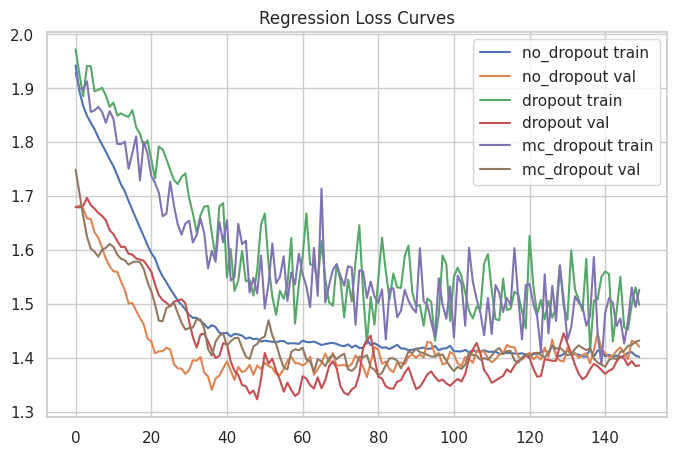

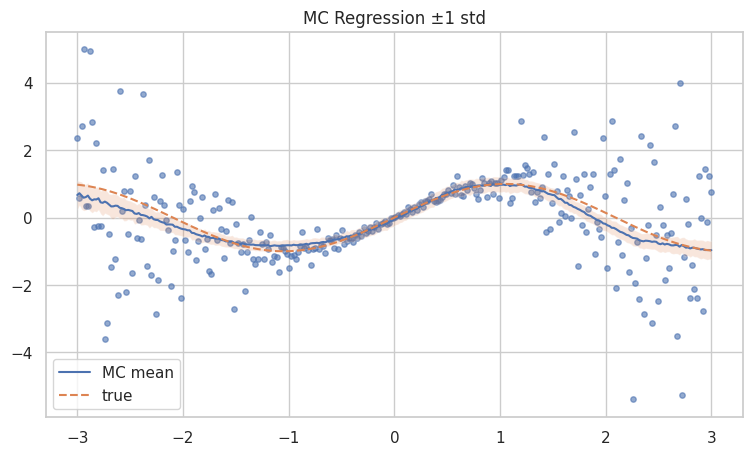

In [ ]:
reg_model_fn = lambda dropout_p, dropout_type: make_regression_model(1, [64,64], dropout_p, dropout_type)
reg_results = run_three_variants(reg_model_fn, reg_train_loader, reg_val_loader, n_epochs=150, lr=1e-3)

plot_loss_curves(reg_results, "Regression Loss Curves")

X_all = torch.from_numpy(scaler_reg.transform(X_reg)).float()
model_mc = reg_results["mc_dropout"]["model"]
mean, std, preds = mc_dropout_predict(model_mc, X_all, T=200)

mean = mean.squeeze().cpu().numpy()
std = std.squeeze().cpu().numpy()
x_plot = X_reg.ravel()
order = np.argsort(x_plot)

plt.figure(figsize=(9,5))
plt.scatter(X_reg, y_reg, s=15, alpha=0.6)
plt.plot(x_plot[order], mean[order], label="MC mean")
plt.fill_between(x_plot[order], (mean-std)[order], (mean+std)[order], alpha=0.2)
plt.plot(x_plot[order], y_reg_true[order], "--", label="true")
plt.legend(); plt.title("MC Regression ±1 std"); plt.show()


Training no_dropout
Training dropout
Training mc_dropout


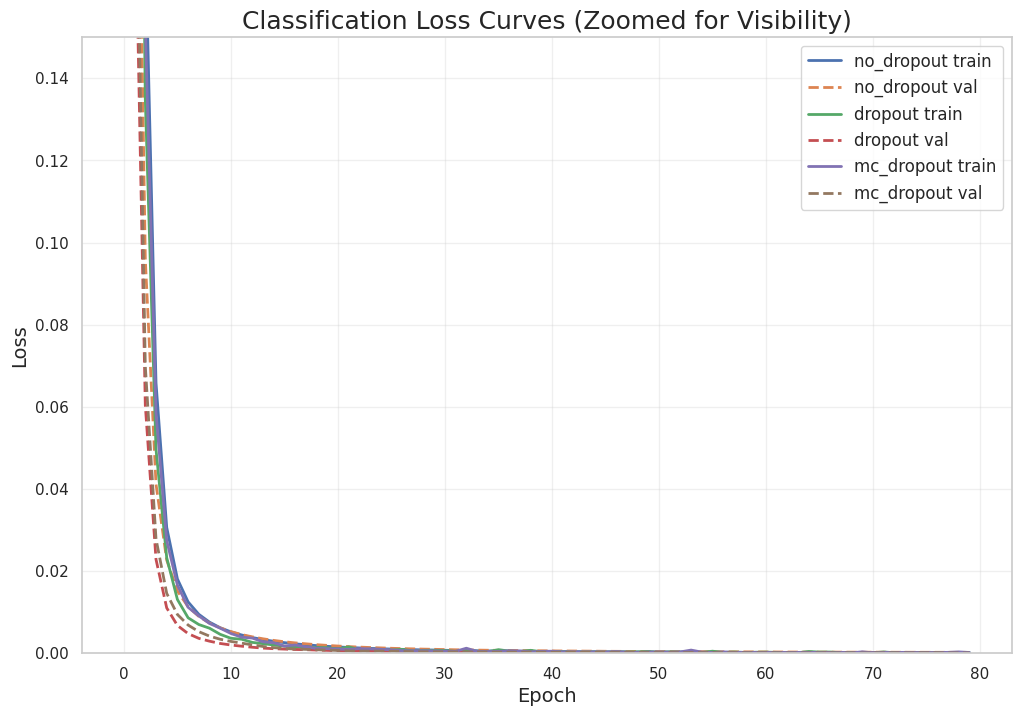

Deterministic accuracies: no=1.0000, dropout(det)=1.0000
MC accuracy: 1.0000
Entropy: mean=0.0016, std=0.0075
ECE: 0.0002


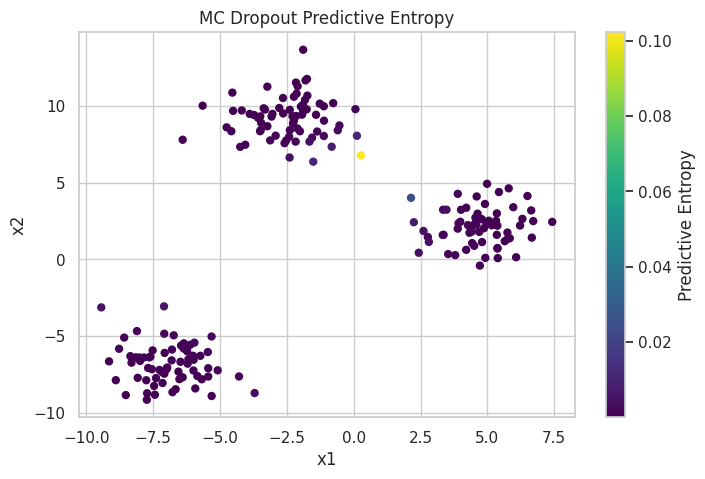

In [ ]:
clf_model_fn = lambda dropout_p, dropout_type: make_classification_model(
    input_dim=2,
    n_classes=3,
    hidden=[128, 64],
    dropout_p=dropout_p,
    dropout_type=dropout_type
)

clf_results = run_three_variants(
    clf_model_fn,
    clf_train_loader,
    clf_val_loader,
    n_epochs=80,
    lr=1e-3
)

plt.figure(figsize=(12, 8))
plt.ylim(0, 0.15)
plt.grid(True, alpha=0.3)

for name, v in clf_results.items():
    h = v["history"]
    plt.plot(h["train_loss"], label=f"{name} train", linewidth=2)
    plt.plot(h["val_loss"], label=f"{name} val", linewidth=2, linestyle="--")

plt.xlabel("Epoch", fontsize=14)
plt.ylabel("Loss", fontsize=14)
plt.title("Classification Loss Curves (Zoomed for Visibility)", fontsize=18)
plt.legend(fontsize=12)
plt.show()

acc_no = eval_classification(clf_results["no_dropout"]["model"], clf_val_loader)
acc_drop = eval_classification(clf_results["dropout"]["model"], clf_val_loader)
print(f"Deterministic accuracies: no={acc_no:.4f}, dropout(det)={acc_drop:.4f}")

Xv = torch.from_numpy(X_clf_val_s).float()
model_mc = clf_results["mc_dropout"]["model"]

mean_logits, std_logits, all_logits = mc_dropout_predict(
    model_mc, Xv, T=200, apply_softmax=False
)

all_probs = F.softmax(all_logits, dim=-1).cpu().numpy()   # (T, N, C)
mean_probs = all_probs.mean(axis=0)                       # (N, C)

preds = mean_probs.argmax(axis=-1)
mc_acc = (preds == y_clf_val).mean()
print(f"MC accuracy: {mc_acc:.4f}")


ent = entropy_from_probs(mean_probs)
print(f"Entropy: mean={ent.mean():.4f}, std={ent.std():.4f}")


ece_val = compute_ece(mean_probs, y_clf_val, n_bins=15)
print(f"ECE: {ece_val:.4f}")


plt.figure(figsize=(8,5))
plt.scatter(X_clf_val[:,0], X_clf_val[:,1], c=ent, cmap="viridis", s=25)
plt.colorbar(label="Predictive Entropy")
plt.title("MC Dropout Predictive Entropy")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()


In [ ]:

from tabulate import tabulate

def get_probs(model, X):
    model.eval()
    xb = torch.from_numpy(X).float().to(device)
    with torch.no_grad():
        out = model(xb)
        return F.softmax(out, dim=-1).cpu().numpy()

probs_no = get_probs(clf_results["no_dropout"]["model"], X_clf_val_s)
probs_drop = get_probs(clf_results["dropout"]["model"], X_clf_val_s)

acc_no = (probs_no.argmax(-1)==y_clf_val).mean()
acc_drop = (probs_drop.argmax(-1)==y_clf_val).mean()

ece_no = compute_ece(probs_no, y_clf_val)
ece_drop = compute_ece(probs_drop, y_clf_val)
ece_mc = compute_ece(mean_probs, y_clf_val)

table = [
    ["no_dropout", acc_no, ece_no],
    ["dropout", acc_drop, ece_drop],
    ["mc_dropout", mc_acc, ece_mc],
]

print(tabulate(table, headers=["variant","acc","ece"], tablefmt="github"))


| variant    |   acc |         ece |
|------------|-------|-------------|
| no_dropout |     1 | 0.000207067 |
| dropout    |     1 | 5.91266e-05 |
| mc_dropout |     1 | 0.000213802 |


Epoch 1 train=1.9391 val=1.7382
Epoch 10 train=1.8837 val=1.6619
Epoch 20 train=1.9031 val=1.5837
Epoch 30 train=1.8201 val=1.6365
Epoch 40 train=1.8471 val=1.7086
Epoch 50 train=1.7436 val=1.6174
Epoch 60 train=1.6052 val=1.4618
Epoch 70 train=1.8101 val=1.7015
Epoch 80 train=1.6904 val=1.5730


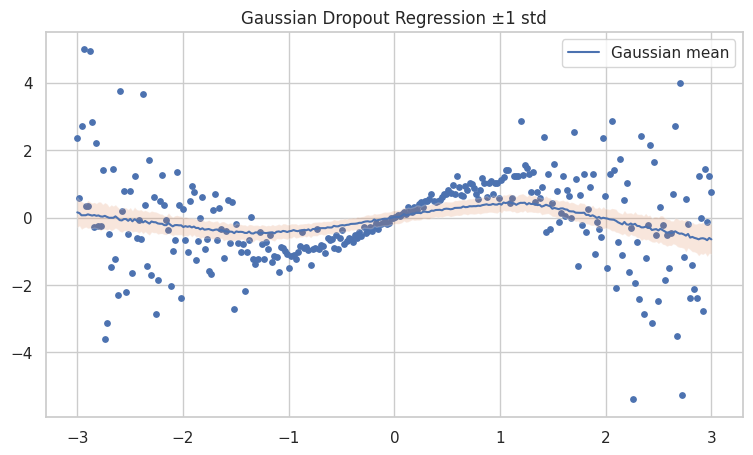

In [ ]:

gauss_reg = make_regression_model(1, [64,64], dropout_p=0.2, dropout_type="gaussian").to(device)
hist = fit(gauss_reg, reg_train_loader, reg_val_loader, n_epochs=80, lr=1e-3)

mean_g, std_g, _ = mc_dropout_predict(gauss_reg, torch.from_numpy(scaler_reg.transform(X_reg)).float(), T=200)
mean_g = mean_g.squeeze().cpu().numpy()
std_g = std_g.squeeze().cpu().numpy()

order = np.argsort(x_plot)
plt.figure(figsize=(9,5))
plt.scatter(X_reg, y_reg, s=15)
plt.plot(x_plot[order], mean_g[order], label="Gaussian mean")
plt.fill_between(x_plot[order], (mean_g-std_g)[order], (mean_g+std_g)[order], alpha=0.2)
plt.legend(); plt.title("Gaussian Dropout Regression ±1 std"); plt.show()


In [ ]:

import torchvision
import torchvision.transforms as T

train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomCrop(32, padding=4),
    T.ToTensor(),
    T.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010))
])
test_tf = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914,0.4822,0.4465),(0.2023,0.1994,0.2010))
])

train_cifar = torchvision.datasets.CIFAR10("./data", True, download=True, transform=train_tf)
test_cifar  = torchvision.datasets.CIFAR10("./data", False, download=True, transform=test_tf)

train_loader_cifar = torch.utils.data.DataLoader(train_cifar, batch_size=128, shuffle=True, num_workers=2)
test_loader_cifar  = torch.utils.data.DataLoader(test_cifar, batch_size=256, shuffle=False, num_workers=2)

class VGGBlock(nn.Module):
    def __init__(self, in_c, out_c, use_pool=True, dropout_p=0.0):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.ReLU(),
            nn.Dropout(dropout_p)
        )
        self.pool = nn.MaxPool2d(2) if use_pool else nn.Identity()

    def forward(self, x):
        return self.pool(self.conv(x))

class VGGStyle(nn.Module):
    def __init__(self, num_classes=10, dropout_p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            VGGBlock(3,64,True,dropout_p),
            VGGBlock(64,128,True,dropout_p),
            VGGBlock(128,256,True,dropout_p),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4*4*256, 512),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(512,num_classes),
        )
    def forward(self,x):
        return self.classifier(self.features(x))

vgg_no = VGGStyle(dropout_p=0.0).to(device)
vgg_drop = VGGStyle(dropout_p=0.3).to(device)
vgg_mc = VGGStyle(dropout_p=0.3).to(device)

def train_cifar_epoch(model, loader, opt):
    model.train()
    total=0; n=0
    for xb,yb in loader:
        xb=xb.to(device); yb=yb.to(device)
        opt.zero_grad()
        out=model(xb)
        loss=F.cross_entropy(out,yb)
        loss.backward()
        opt.step()
        total += loss.item()*xb.size(0)
        n+=xb.size(0)
    return total/n

@torch.no_grad()
def eval_cifar(model, loader):
    model.eval()
    total=0; correct=0; n=0
    for xb,yb in loader:
        xb=xb.to(device); yb=yb.to(device)
        out=model(xb)
        loss=F.cross_entropy(out,yb)
        total+=loss.item()*xb.size(0)
        preds=out.argmax(-1)
        correct+=(preds==yb).sum().item()
        n+=xb.size(0)
    return total/n, correct/n

def fit_cifar(model, train_loader, test_loader, n_epochs=5, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist={"train_loss":[], "test_loss":[], "test_acc":[]}
    for e in range(1, n_epochs+1):
        tr=train_cifar_epoch(model, train_loader, opt)
        tl,ta=eval_cifar(model, test_loader)
        hist["train_loss"].append(tr)
        hist["test_loss"].append(tl)
        hist["test_acc"].append(ta)
        print(f"Epoch {e}: tr={tr:.4f} tl={tl:.4f} acc={ta:.4f}")
    return hist


100%|██████████| 170M/170M [00:05<00:00, 29.6MB/s]


cuda
DeepVGG(
  (features): Sequential(
    (0): Block(
      (conv): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (1): Block(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(128, eps=1

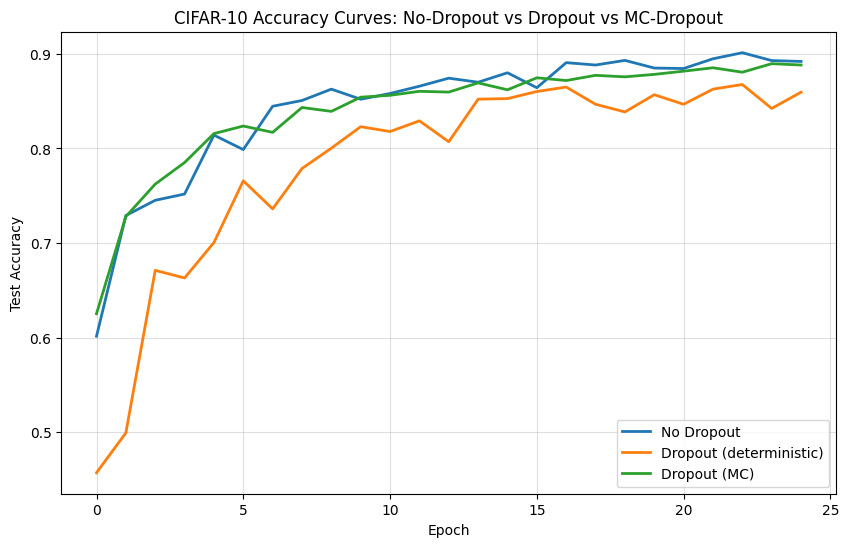

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import numpy as np
import time
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomCrop(32, padding=4),
    T.ToTensor(),
    T.Normalize((0.4914,0.4822,0.4465), (0.2023,0.1994,0.2010))
])

test_tf = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914,0.4822,0.4465), (0.2023,0.1994,0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_tf)
testset  = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_tf)

train_loader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)
test_loader  = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=2)

class Block(nn.Module):
    def __init__(self, inp, out, p):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(inp, out, 3, padding=1),
            nn.BatchNorm2d(out),
            nn.ReLU(inplace=True),
            nn.Conv2d(out, out, 3, padding=1),
            nn.BatchNorm2d(out),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(p)

    def forward(self, x):
        x = self.conv(x)
        x = self.drop(x)
        x = self.pool(x)
        return x

class DeepVGG(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.features = nn.Sequential(
            Block(3,   64, p),
            Block(64, 128, p),
            Block(128,256, p),
            Block(256,256, p),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*2*2, 512),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(512, 10)
        )
        self._init()

    def _init(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

vgg_no = DeepVGG(p=0.0).to(device)
vgg_do = DeepVGG(p=0.3).to(device)

print(vgg_no)
print(vgg_do)

loss_fn = nn.CrossEntropyLoss()
opt_no = torch.optim.Adam(vgg_no.parameters(), lr=1e-3)
opt_do = torch.optim.Adam(vgg_do.parameters(), lr=1e-3)

def train_epoch(model, opt):
    model.train()
    loss_sum = 0
    n = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward()
        opt.step()
        loss_sum += loss.item() * xb.size(0)
        n += xb.size(0)
    return loss_sum / n

@torch.no_grad()
def test_acc(model, loader=test_loader):
    model.eval()
    correct = 0
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        pred = out.argmax(dim=1)
        correct += (pred == yb).sum().item()
        n += xb.size(0)
    return correct / n

@torch.no_grad()
def test_acc_mc(model, T=20):
    model.train()
    preds = []
    for t in range(T):
        all_preds = []
        for xb, _ in test_loader:
            xb = xb.to(device)
            out = model(xb)
            out = F.softmax(out, dim=1)
            all_preds.append(out.cpu().numpy())
        preds.append(np.concatenate(all_preds))
    preds = np.stack(preds, axis=0)
    mean_probs = preds.mean(axis=0)
    pred = mean_probs.argmax(axis=1)

    ys = np.concatenate([y.numpy() for _, y in test_loader])
    return (pred == ys).mean()

EPOCHS = 25
acc_no, acc_do_det, acc_do_mc = [], [], []

for ep in range(1, EPOCHS+1):
    t0 = time.time()

    l1 = train_epoch(vgg_no, opt_no)
    a1 = test_acc(vgg_no)
    acc_no.append(a1)

    l2 = train_epoch(vgg_do, opt_do)
    a2 = test_acc(vgg_do)
    a3 = test_acc_mc(vgg_do, T=10)
    acc_do_det.append(a2)
    acc_do_mc.append(a3)

    print(f"EP {ep}: no-drop={a1:.3f}  drop={a2:.3f}  mc={a3:.3f}   time={time.time()-t0:.1f}s")

plt.figure(figsize=(10,6))
plt.plot(acc_no, label="No Dropout", linewidth=2)
plt.plot(acc_do_det, label="Dropout (deterministic)", linewidth=2)
plt.plot(acc_do_mc, label="Dropout (MC)", linewidth=2)
plt.grid(True, alpha=0.4)
plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("CIFAR-10 Accuracy Curves: No-Dropout vs Dropout vs MC-Dropout")
plt.legend()
plt.show()
